In [4]:
from langgraph.graph import StateGraph,START,END
from typing import TypedDict



In [6]:
class SummaryState(TypedDict):
    runs:int
    ball:int
    sr:float #strike rate
    bp:float #boundary percentage
    bpb:float # ball per boundary
    summary:str #summary

    four:int
    six:int


In [7]:
def strike_rate(state:SummaryState):
    if state['ball'] == 0:
        sr= 0
    else:
        sr = (state['runs']/state['ball'])*100
    return {'sr': sr}

In [8]:
def boundary_percentage(state:SummaryState):
    if state['runs'] == 0:
        bp = 0
    else:
        bp = (state['four']*4 + state['six']*6)/state['runs']
    return {'bp': bp}

In [9]:
def ball_per_boundary(state:SummaryState):
    if state['four'] + state['six'] == 0:
        bpb = 0
    else:
        bpb = state['ball']/(state['four'] + state['six'])
    return {'bpb': bpb}

In [10]:
def summary(state:SummaryState):
    summary = f"Runs: {state['runs']}, Balls: {state['ball']}, Strike Rate: {state['sr']:.2f}, Boundary Percentage: {state['bp']:.2f}, Balls per Boundary: {state['bpb']:.2f}"
    return {'summary': summary}


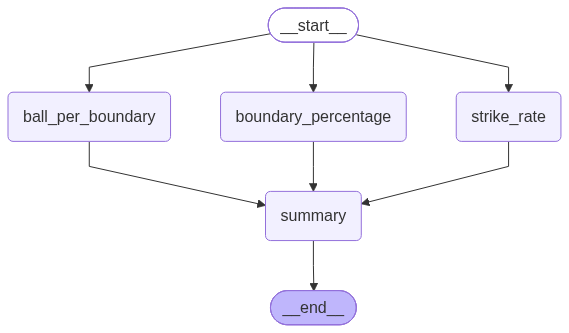

In [12]:
graph = StateGraph(SummaryState)

graph.add_node('strike_rate',strike_rate)
graph.add_node('boundary_percentage',boundary_percentage)
graph.add_node('ball_per_boundary',ball_per_boundary)
graph.add_node('summary',summary)

graph.add_edge(START,'strike_rate')
graph.add_edge(START,'boundary_percentage')
graph.add_edge(START,'ball_per_boundary')

graph.add_edge('strike_rate','summary')
graph.add_edge('boundary_percentage','summary')     
graph.add_edge('ball_per_boundary','summary')

graph.add_edge('summary',END)

workflow=graph.compile()

workflow





In [14]:
intial_state = {
    'runs': 100,
    'ball': 50,
    'four': 6,
    'six': 4
}

workflow.invoke(intial_state)

{'runs': 100,
 'ball': 50,
 'sr': 200.0,
 'bp': 0.48,
 'bpb': 5.0,
 'summary': 'Runs: 100, Balls: 50, Strike Rate: 200.00, Boundary Percentage: 0.48, Balls per Boundary: 5.00',
 'four': 6,
 'six': 4}